In [28]:
import pandas as pd
import numpy as np
import seaborn as sns

In [29]:
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [30]:
df.dtypes

Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [33]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000
mean,11.359892,-72.527631,39.935881,-72.525292,39.923890,1.684543
std,9.901760,11.437815,7.720558,13.117408,6.794829,1.385995
min,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [32]:
# Remove unnecessary columns
df.drop(columns=["Unnamed: 0", "key"], errors="ignore", inplace=True)

# Remove missing values
df.dropna(inplace=True)

In [34]:
# Remove invalid fare and passenger values
df = df[(df["fare_amount"] > 0) &
         (df["passenger_count"] > 0) &
         (df["passenger_count"] <= 6)]

# Remove invalid NYC coordinates
df = df[df["pickup_latitude"].between(40, 42) &
        df["pickup_longitude"].between(-75, -72) &
        df["dropoff_latitude"].between(40, 42) &
        df["dropoff_longitude"].between(-75, -72)]

print(df.describe())

         fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
count  195100.000000     195100.000000    195100.000000      195100.000000   
mean       11.350275        -73.975113        40.750976         -73.974176   
std         9.802850          0.039402         0.030144           0.039242   
min         0.010000        -74.719883        40.002405         -74.728123   
25%         6.000000        -73.992273        40.736453         -73.991597   
50%         8.500000        -73.982110        40.753304         -73.980541   
75%        12.500000        -73.968361        40.767549         -73.965380   
max       499.000000        -72.750302        41.366138         -72.759090   

       dropoff_latitude  passenger_count  
count     195100.000000    195100.000000  
mean          40.751272         1.689764  
std            0.033545         1.305591  
min           40.005487         1.000000  
25%           40.735332         1.000000  
50%           40.753747         1.00000

Before removing outliers: (195100, 7)


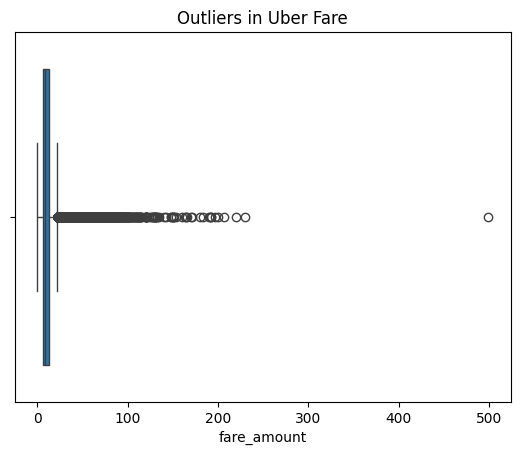

After removing outliers: (178392, 7)


In [35]:
# Before removing outliers
print("Before removing outliers:", df.shape)

Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

import matplotlib.pyplot as plt
sns.boxplot(x=df["fare_amount"])
plt.title("Outliers in Uber Fare")
plt.show()

# Remove outliers
df = df[df["fare_amount"].between(lower, upper)]

# After removing outliers
print("After removing outliers:", df.shape)

In [36]:
# Check correlation
print(df.corr(numeric_only=True)["fare_amount"].sort_values(ascending=False))

fare_amount          1.000000
dropoff_longitude    0.073951
passenger_count      0.012437
pickup_longitude     0.001255
pickup_latitude     -0.075714
dropoff_latitude    -0.086857
Name: fare_amount, dtype: float64


In [37]:
from sklearn.model_selection import train_test_split

features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count"
]
X = df[features]

y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142713, 5)
Testing data: (35679, 5)


In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Linear Regression R2:",
      r2_score(y_test, y_pred_lr))

Linear Regression R2: 0.031539744314886486


In [39]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest R2:",
      r2_score(y_test, y_pred_rf))

Random Forest R2: 0.7169424408663032


In [40]:
from sklearn.metrics import mean_squared_error

print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_lr)))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_rf)))

Linear Regression RMSE: 4.076108381932702
Random Forest RMSE: 2.20364788300678


In [41]:
print("Actual fare:", y_test.values[:5])

print("Linear Regression prediction:", y_pred_lr[:5])

print("Random Forest prediction:", y_pred_rf[:5])

Actual fare: [ 8.1  6.5 11.3 10.1 10.9]
Linear Regression prediction: [ 8.91959367  8.28965129  9.97766189  9.27030995 10.43782674]
Random Forest prediction: [10.89   7.508 12.836 11.23  13.82 ]
